# 4.2 Texte OCR + similarité cosinus : Dataset 2 (1er extrait, 30 000 images)

Même méthode qu'en 3.2, sur un échantillon OCR de 1 800 documents (300 par classe, 360 en test).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from nltk.corpus import stopwords
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize

from outils_4 import load_ocr_sample, classify_by_cosine

train_df, test_df = load_ocr_sample()

MOTS_VIDES = stopwords.words("english")
for df in (train_df, test_df):
    df["texte_sans_mots_vides"] = df["text"].apply(
        lambda texte: " ".join(mot for mot in texte.split() if mot.lower() not in MOTS_VIDES))
print(f"Train : {len(train_df)} | Test : {len(test_df)}")

Train : 1440 | Test : 360


## 1. Quatre variantes TF-IDF + centroïdes + cosinus

In [2]:
variantes = {
    # nom : (vectoriseur, colonne de texte)
    "mots": (TfidfVectorizer(ngram_range=(1, 2), strip_accents="unicode", sublinear_tf=True), "text"),
    "mots, sans mots vides": (TfidfVectorizer(ngram_range=(1, 2), strip_accents="unicode", sublinear_tf=True,
                                              stop_words=MOTS_VIDES), "text"),
    "caractères": (TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True), "text"),
    "caractères, sans mots vides": (TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True),
                                    "texte_sans_mots_vides"),
}

lignes, predictions, similarites = [], {}, {}
for nom, (vectoriseur, colonne) in variantes.items():
    X_train = vectoriseur.fit_transform(train_df[colonne])  # fit sur le train seulement
    X_test = vectoriseur.transform(test_df[colonne])
    predictions[nom], similarites[nom] = classify_by_cosine(X_train, train_df["label"], X_test)
    if nom == "caractères":
        X_train_car, X_test_car = X_train, X_test  # resservent pour le K-means plus bas
    lignes.append({"variante": nom, "taille du vocabulaire": len(vectoriseur.vocabulary_),
                   "accuracy": accuracy_score(test_df["label"], predictions[nom])})

pd.DataFrame(lignes).round(3)

,variante,taille du vocabulaire,accuracy
0,mots,150244,0.769
1,"mots, sans mots vides",135716,0.775
2,caractères,194391,0.806
3,"caractères, sans mots vides",194199,0.797


## 2. Matrices de confusion : mots / caractères

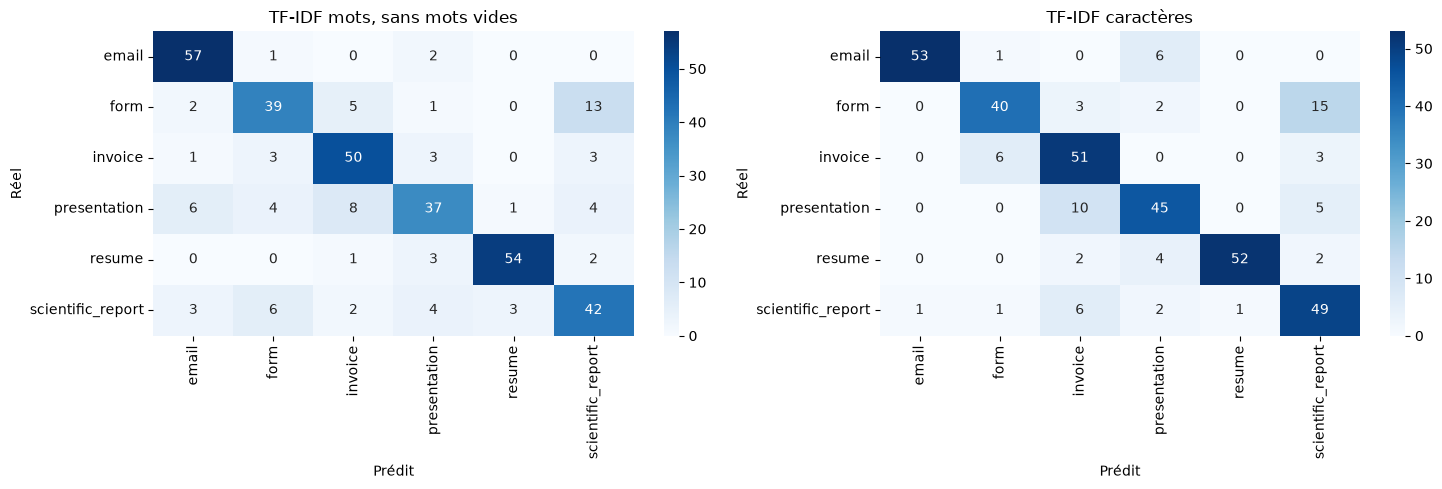

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, nom in zip(axes, ["mots, sans mots vides", "caractères"]):
    matrice = pd.crosstab(test_df["label"], predictions[nom], rownames=["Réel"], colnames=["Prédit"])
    sns.heatmap(matrice, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(f"TF-IDF {nom}")
plt.tight_layout()
plt.show()

## 3. Mélanger les scores des mots et des caractères

`alpha × score mots + (1 − alpha) × score caractères`, avec alpha de 0 à 1. C'est mesuré directement
sur le test : ça donne juste une idée du gain possible.

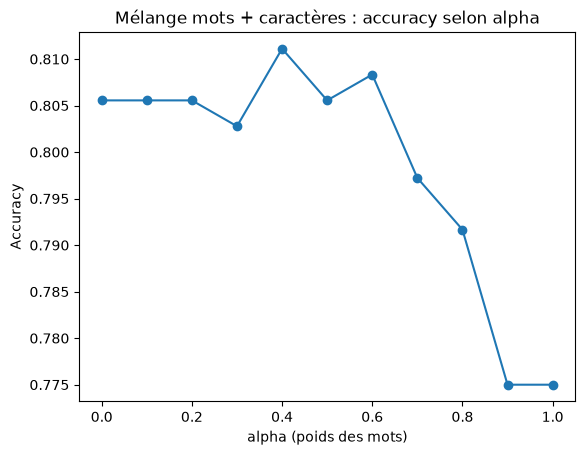

Caractères seuls : 80.6% | meilleur mélange : 81.1% (alpha = 0.4)


In [4]:
alphas = np.round(np.arange(0, 1.01, 0.1), 1)
accuracies = []
for alpha in alphas:
    melange = alpha * similarites["mots, sans mots vides"] + (1 - alpha) * similarites["caractères"]
    accuracies.append(accuracy_score(test_df["label"], melange.idxmax(axis=1)))

plt.plot(alphas, accuracies, marker="o")
plt.xlabel("alpha (poids des mots)")
plt.ylabel("Accuracy")
plt.title("Mélange mots + caractères : accuracy selon alpha")
plt.show()
print(f"Caractères seuls : {accuracies[0]:.1%} | meilleur mélange : {max(accuracies):.1%} (alpha = {alphas[np.argmax(accuracies)]})")

## 4. Plusieurs centroïdes par classe (K-means)

Une classe peut avoir plusieurs « styles » de documents : `k` centroïdes par classe au lieu d'un.

In [5]:
X_car = X_train_car.toarray()
y_train = train_df["label"].to_numpy()
classes = sorted(set(y_train))
lignes = []
for k in [1, 2, 3, 4, 5]:
    centroides, proprietaires = [], []
    for classe in classes:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_car[y_train == classe])
        centroides.append(normalize(kmeans.cluster_centers_))
        proprietaires += [classe] * k
    plus_proche = cosine_similarity(X_test_car, np.vstack(centroides)).argmax(axis=1)
    lignes.append({"k": k, "accuracy": accuracy_score(test_df["label"], np.array(proprietaires)[plus_proche])})

pd.DataFrame(lignes).round(3)

,k,accuracy
0,1,0.806
1,2,0.789
2,3,0.819
3,4,0.814
4,5,0.797


Le score bouge de quelques points selon `k`, sans tendance : sur 360 documents, c'est du bruit.